# Chapter 2: Data and Sampling Distributions
> (c) 2019-2026 Peter C. Bruce, Andrew Bruce, Peter Gedeck

In [1]:
from scipy import stats
from sklearn.utils import resample
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns

random.seed(123)

# Location of the data files. Adjust this path if you keep the data
# files in a different directory.
from pathlib import Path
DATA_DIR = Path('../data')


## Data and Sampling Distributions
### Sampling Distribution of a Statistic

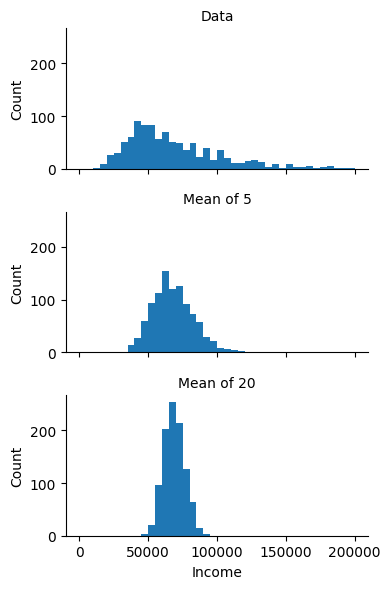

In [1]:
loans_income = pd.read_csv(DATA_DIR / "loans_income.csv").squeeze("columns")

sample_data = pd.DataFrame({
    "income": loans_income.sample(1000),
    "type": "Data",
})
sample_mean_05 = pd.DataFrame({
    "income": [loans_income.sample(5).mean() for _ in range(1000)],
    "type": "Mean of 5",
})
sample_mean_20 = pd.DataFrame({
    "income": [loans_income.sample(20).mean() for _ in range(1000)],
    "type": "Mean of 20",
})
results = pd.concat([sample_data, sample_mean_05, sample_mean_20])

g = sns.FacetGrid(results, col="type", col_wrap=1, height=2, aspect=2)
g.map(plt.hist, "income", range=[0, 200000], bins=40)
g.set_axis_labels("Income", "Count")
g.set_titles("{col_name}")

plt.tight_layout()
plt.show()

### The Bootstrap

In [1]:
res = stats.bootstrap([loans_income], np.median, n_resamples=1000,
    method="basic")

print("Bootstrap Statistics:")
print(f"original: {np.median(loans_income)}")
print(f"bias: {np.mean(res.bootstrap_distribution) - np.median(loans_income)}")
print(f"std. error: {res.standard_error}")
print(f"confidence interval: {res.confidence_interval}")

Bootstrap Statistics:
original: 62000.0
bias: -73.80999999999767
std. error: 219.22212306069665
confidence interval: ConfidenceInterval(low=np.float64(62000.0), high=np.float64(62936.8625))


In [1]:
# alternative using scikit-learns's resample function

results = []
for _ in range(1000):
    sample = resample(loans_income)
    results.append(sample.median())
results = pd.Series(results)
print("Bootstrap Statistics:")
print(f"original: {loans_income.median()}")
print(f"bias: {results.mean() - loans_income.median()}")
print(f"std. error: {results.std()}")

Bootstrap Statistics:
original: 62000.0
bias: -73.30299999999988
std. error: 215.6922700199206


### Normal Distribution
#### Standard Normal and QQ-Plots

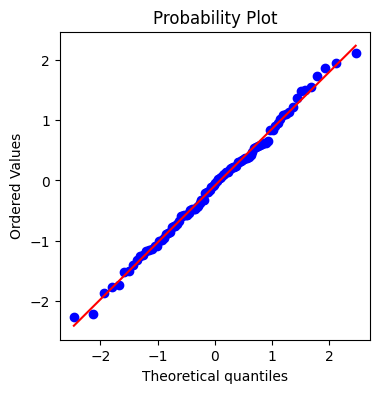

In [1]:
fig, ax = plt.subplots(figsize=(4, 4))
norm_sample = stats.norm.rvs(size=100)
stats.probplot(norm_sample, plot=ax)
plt.show()

### Long-Tailed Distributions

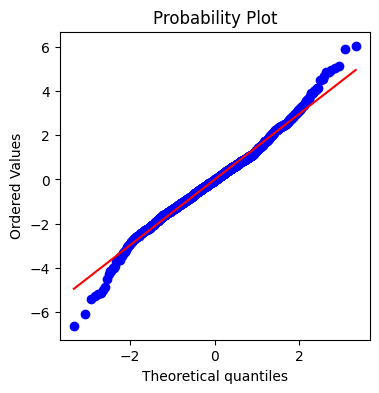

In [1]:
sp500_px = pd.read_csv(DATA_DIR / "sp500_data.csv.gz")

nflx = sp500_px.NFLX
nflx = np.diff(np.log(nflx[nflx > 0]))
fig, ax = plt.subplots(figsize=(4, 4))
stats.probplot(nflx, plot=ax)
plt.show()

### Binomial Distribution

In [1]:
print(stats.binom.pmf(2, n=5, p=0.1))
print(stats.binom.cdf(2, n=5, p=0.1))

0.07289999999999995
0.99144


### Poisson and Related Distributions
#### Poisson Distributions

In [1]:
stats.poisson.rvs(2, size=100)

array([3, 2, 2, 2, 2, 2, 3, 2, 2, 1, 2, 2, 3, 2, 3, 3, 1, 2, 2, 3, 2, 0,
       2, 2, 0, 4, 3, 7, 4, 4, 3, 2, 0, 3, 0, 2, 0, 1, 5, 0, 2, 1, 3, 4,
       2, 0, 5, 1, 0, 3, 1, 1, 3, 3, 2, 7, 1, 4, 1, 1, 0, 1, 2, 1, 0, 1,
       3, 1, 2, 1, 1, 0, 2, 4, 0, 4, 1, 2, 1, 2, 2, 4, 5, 1, 0, 4, 2, 2,
       6, 3, 1, 4, 1, 1, 4, 4, 3, 1, 0, 3])

#### Exponential Distribution

In [1]:
stats.expon.rvs(scale=1 / 0.2, size=100)
stats.expon.rvs(scale=5, size=100)

array([3.27564215e+00, 1.16665057e-02, 3.83567819e-01, 1.79851740e+01,
       3.06524125e+00, 4.30454632e-01, 1.53305775e+00, 3.55062067e+00,
       1.20210218e-01, 3.45994087e-01, 1.87331647e+01, 4.76161768e+00,
       3.53919666e-01, 7.61549296e+00, 2.97461026e+00, 9.17135721e+00,
       8.70028459e+00, 6.12090011e+00, 2.60203143e-01, 1.99826222e-01,
       5.94910389e-01, 3.12185436e+00, 1.38424203e+00, 1.08075120e+01,
       5.23336977e+00, 2.97420772e+00, 1.00199176e+01, 1.03569154e+01,
       1.02960506e+01, 1.99275448e+00, 1.99071572e+00, 1.51653842e+00,
       5.93847762e+00, 5.32268797e+00, 1.23737443e+00, 1.69869201e+01,
       3.28280495e+00, 2.60990166e+00, 2.12998786e+00, 1.19044724e+00,
       6.14755805e-01, 6.48693894e+00, 3.81119078e+00, 7.19714258e+00,
       1.07514466e+01, 7.23997570e+00, 8.69081682e-01, 1.86320616e+00,
       4.56964059e+00, 1.01873471e+01, 1.15881001e+00, 4.79416272e+00,
       5.30361908e+00, 3.58386831e+01, 6.02527237e+00, 6.18216896e+00,
      

#### Weibull Distribution

In [1]:
stats.weibull_min.rvs(1.5, scale=5000, size=100)

array([ 6148.17326166,  2559.5501786 ,  4797.90008181,  5119.28184694,
         971.34336042,  5695.29383607,  3102.87829001,  2561.06991764,
        6416.38477491,  6650.43924697,  4478.7233529 ,  2190.60384375,
        2438.03936165,  6967.94943718,  7220.24708724,  6628.79331904,
        2223.59417868,  8174.82387869,  2571.59034264,   253.58345688,
         865.67423751,  6383.18534381,  2821.00755567,  8614.48394994,
        6334.00284117,  5119.63373057,  3938.80641203,  5042.8020368 ,
        2092.77460589,  5857.70484354,  3701.71382659,   468.29351905,
        5001.70432072, 12175.23488254,  4399.2895717 ,  2771.75931374,
        3950.08940957,  2762.03346351,  1475.95590739,   836.48835131,
         264.29494174,  2031.80015238,  1339.96096716,  6190.05431234,
         458.26940724,  4039.23267505,  3491.04191469,  1856.33760111,
        9897.84319011,   737.27123084,  1772.66477783,  4015.28946448,
        5447.85887708,  9622.31921084,  3440.70492024,  5227.84319895,
      

# Supplementary Material
## Figure 2-9 Bootstrap confidence interval for the annual income of loan applicants, based on a sample of 20

68760.51844
55734.1


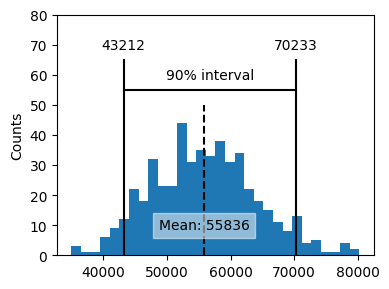

In [1]:
print(loans_income.mean())
np.random.seed(seed=3)

# create a sample of 20 loan income data
sample20 = resample(loans_income, n_samples=20, replace=False)
print(sample20.mean())
results = []
for _ in range(500):
    sample = resample(sample20)
    results.append(sample.mean())
results = pd.Series(results)

confidence_interval = list(results.quantile([0.05, 0.95]))
ax = results.plot.hist(bins=30, figsize=(4, 3))
ax.plot(confidence_interval, [55, 55], color="black")
for x in confidence_interval:
    ax.plot([x, x], [0, 65], color="black")
    ax.text(x, 70, f"{x:.0f}", horizontalalignment="center", verticalalignment="center")
ax.text(sum(confidence_interval) / 2, 60, "90% interval",
        horizontalalignment="center", verticalalignment="center")

meanIncome = results.mean()
ax.plot([meanIncome, meanIncome], [0, 50], color="black", linestyle="--")
ax.text(meanIncome, 10, f"Mean: {meanIncome:.0f}",
        bbox={"facecolor": "white", "edgecolor": "white", "alpha": 0.5},
        horizontalalignment="center", verticalalignment="center")
ax.set_ylim(0, 80)
ax.set_ylabel("Counts")

plt.tight_layout()
plt.show()

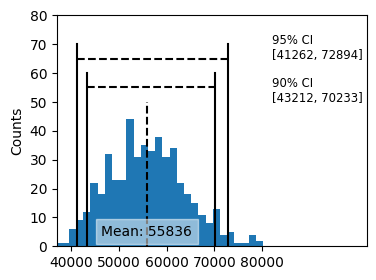

In [1]:
np.random.seed(seed=3)
# create a sample of 20 loan income data
sample20 = resample(loans_income, n_samples=20, replace=False)

results = []
for _ in range(500):
    sample = resample(sample20)
    results.append(sample.mean())
results = pd.Series(results)

confidence_interval = list(results.quantile([0.05, 0.95]))
ax = results.plot.hist(bins=30, figsize=(4, 3), color="C1")
ax.plot(confidence_interval, [55, 55], color="black", linestyle="--")
for x in confidence_interval:
    ax.plot([x, x], [0, 60], color="black")
ax.text(82000, 50,
        f"90% CI\n[{confidence_interval[0]:.0f}, {confidence_interval[1]:.0f}]",
       fontsize="small")

confidence_interval = list(results.quantile([0.025, 0.975]))
ax = results.plot.hist(bins=30, figsize=(4, 3))
ax.plot(confidence_interval, [65, 65], color="black", linestyle="--")
for x in confidence_interval:
    ax.plot([x, x], [0, 70], color="black")
ax.text(82000, 65,
        f"95% CI\n[{confidence_interval[0]:.0f}, {confidence_interval[1]:.0f}]",
       fontsize="small")
# ax.text(sum(confidence_interval) / 2, 264, "95 % interval",
#         horizontalalignment="center", verticalalignment="center")

meanIncome = results.mean()
ax.plot([meanIncome, meanIncome], [0, 50], color="black", linestyle="--")
ax.text(meanIncome, 5, f"Mean: {meanIncome:.0f}",
        bbox={"facecolor": "white", "edgecolor": "white", "alpha": 0.5},
        horizontalalignment="center", verticalalignment="center")
ax.set_ylim(0, 80)
ax.set_xlim(37000, 102000)
ax.set_xticks([40000, 50000, 60000, 70000, 80000])
ax.set_ylabel("Counts")
plt.show()

## Visualization of Distributions
### Poisson Distribution

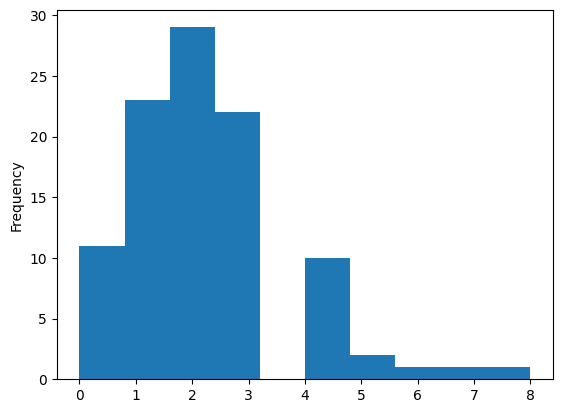

In [1]:
sample = stats.poisson.rvs(2, size=100)
pd.Series(sample).plot.hist()
plt.show()

### Exponential Distribution

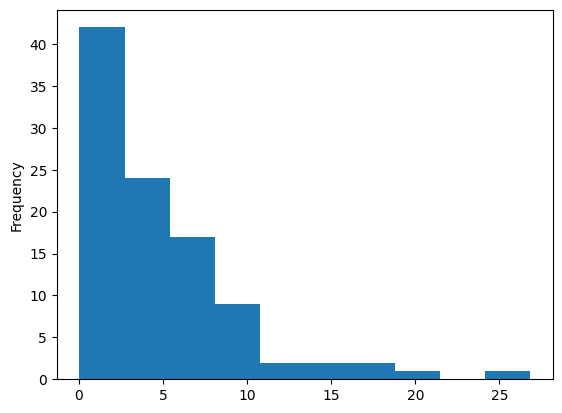

In [1]:
sample = stats.expon.rvs(scale=5, size=100)
pd.Series(sample).plot.hist()
plt.show()

### Weibull Distribution

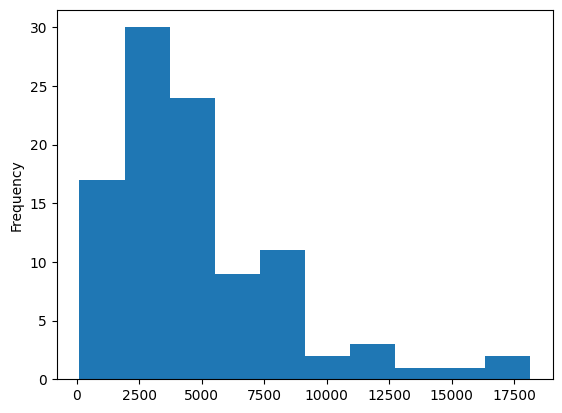

In [1]:
sample = stats.weibull_min.rvs(1.5, scale=5000, size=100)
pd.Series(sample).plot.hist()
plt.show()